# Trustworthy AI - HW4 - Q1
# Amin Aghakasiri - 810101381

### Step 0: Reproducibility

In [40]:
import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib
import sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
from sklearn.inspection import permutation_importance

In [41]:
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)

numpy: 1.26.4
pandas: 2.1.1
scikit-learn: 1.5.0
matplotlib: 3.10.9


In [42]:
SEED = 30
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

In [43]:
DATA_PATH = "./compas-scores-two-years.csv"
df_raw = pd.read_csv(DATA_PATH)
print("\nRaw data shape:", df_raw.shape)


Raw data shape: (7214, 53)


In [44]:
df_raw.columns

Index(['id', 'name', 'first', 'last', 'compas_screening_date', 'sex', 'dob',
       'age', 'age_cat', 'race', 'juv_fel_count', 'decile_score',
       'juv_misd_count', 'juv_other_count', 'priors_count',
       'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_case_number',
       'c_offense_date', 'c_arrest_date', 'c_days_from_compas',
       'c_charge_degree', 'c_charge_desc', 'is_recid', 'r_case_number',
       'r_charge_degree', 'r_days_from_arrest', 'r_offense_date',
       'r_charge_desc', 'r_jail_in', 'r_jail_out', 'violent_recid',
       'is_violent_recid', 'vr_case_number', 'vr_charge_degree',
       'vr_offense_date', 'vr_charge_desc', 'type_of_assessment',
       'decile_score.1', 'score_text', 'screening_date',
       'v_type_of_assessment', 'v_decile_score', 'v_score_text',
       'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1',
       'start', 'end', 'event', 'two_year_recid'],
      dtype='object')

In [45]:
# ProPublica standard filtering
df = df_raw.copy()
df = df[
    (df["days_b_screening_arrest"] >= -30) &
    (df["days_b_screening_arrest"] <= 30) &
    (df["is_recid"] != -1) &
    (df["c_charge_degree"] != "O") &
    (df["score_text"] != "N/A")
].copy()
df["two_year_recid"] = df["two_year_recid"].astype(int)
df["race"] = df["race"].astype(str)
df["sex"] = df["sex"].astype(str)
print("Filtered data shape:", df.shape)
print("Removed rows:", len(df_raw) - len(df))

Filtered data shape: (6172, 53)
Removed rows: 1042


In [46]:
key = df["two_year_recid"].astype(str) + "_" + df["race"].astype(str)
if key.value_counts().min() < 2:
    key = df["two_year_recid"]
train_df, test_df = train_test_split(df, test_size=0.20, random_state=SEED, stratify=key)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (4937, 53)
Test shape: (1235, 53)


### Step 1: Bias Audit

In [47]:
audit_df = df.copy()
base_rate = audit_df.groupby("race")["two_year_recid"].agg(["count", "mean"]).rename(columns={"count": "n", "mean": "base_rate"}).sort_values("base_rate", ascending=False)
base_rate["base_rate"] = base_rate["base_rate"].round(3)
print("Base rate P(Y=1) by race:")
print(base_rate)

Base rate P(Y=1) by race:
                     n  base_rate
race                             
African-American  3175      0.523
Native American     11      0.455
Caucasian         2103      0.391
Hispanic           509      0.371
Other              343      0.362
Asian               31      0.258



COMPAS decile score counts by race:


decile_score       1    2    3    4    5    6    7    8    9    10
race                                                              
African-American  365  346  298  337  323  318  343  301  317  227
Asian              15    4    5    0    1    2    1    2    0    1
Caucasian         605  321  238  243  200  160  113   96   77   50
Hispanic          159   89   73   47   39   27   28   14   17   16
Native American     0    2    1    0    0    2    2    0    2    2
Other             142   60   32   39   19   20    9    7    7    8


<Figure size 1000x500 with 0 Axes>

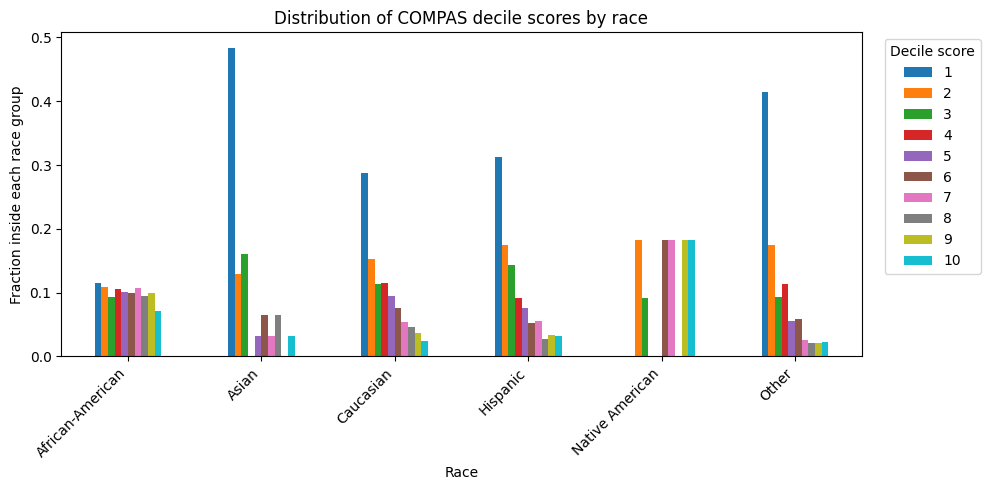

In [48]:
score_count = pd.crosstab(audit_df["race"], audit_df["decile_score"])
score_ratio = pd.crosstab(audit_df["race"], audit_df["decile_score"], normalize="index")
print("\nCOMPAS decile score counts by race:")
print(score_count)
plt.figure(figsize=(10, 5))
score_ratio.plot(kind="bar", figsize=(10, 5))
plt.ylabel("Fraction inside each race group")
plt.xlabel("Race")
plt.title("Distribution of COMPAS decile scores by race")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Decile score", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [49]:
proxy_train = train_df[train_df["race"].isin(["African-American", "Caucasian"])].copy()
proxy_test = test_df[test_df["race"].isin(["African-American", "Caucasian"])].copy()
y_train_race = (proxy_train["race"] == "African-American").astype(int)
y_test_race = (proxy_test["race"] == "African-American").astype(int)
drop_cols = [
    "race",
    "two_year_recid",
    "is_recid",
    "is_violent_recid",
    "decile_score",
    "violent_recid",
    "decile_score.1",
    "score_text",
    "id",
    "dob",
    "compas_screening_date",
    "c_case_number",
    "c_offense_date",
    "c_arrest_date",
    "c_jail_in",
    "c_jail_out",
    "priors_count.1",
    "r_case_number",
    "r_charge_degree",
    "r_days_from_arrest",
    "r_offense_date",
    "r_charge_desc",
    "r_jail_in",
    "r_jail_out",
    "vr_case_number",
    "vr_charge_degree",
    "vr_offense_date",
    "vr_charge_desc",
    "type_of_assessment",
    "v_type_of_assessment",
    "v_score_text",
    "v_decile_score",
    "screening_date"
]
proxy_features = [c for c in proxy_train.columns if c not in drop_cols]
proxy_features = [c for c in proxy_features if c in proxy_test.columns]
print("Number of proxy features:", len(proxy_features))
print(proxy_features)

X_train_proxy = proxy_train[proxy_features]
X_test_proxy = proxy_test[proxy_features]
num_cols = X_train_proxy.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = [c for c in proxy_features if c not in num_cols]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

race_proxy_model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=2000, random_state=SEED))
])

race_proxy_model.fit(X_train_proxy, y_train_race)
race_pred = race_proxy_model.predict(X_test_proxy)
race_prob = race_proxy_model.predict_proba(X_test_proxy)[:, 1]
print("Proxy prediction: African-American vs Caucasian")
print("Accuracy:", round(accuracy_score(y_test_race, race_pred), 3))
print("AUC:", round(roc_auc_score(y_test_race, race_prob), 3))

Number of proxy features: 20
['name', 'first', 'last', 'sex', 'age', 'age_cat', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'v_screening_date', 'in_custody', 'out_custody', 'start', 'end', 'event']
Proxy prediction: African-American vs Caucasian
Accuracy: 0.713
AUC: 0.767


                    feature  importance     std
2                      last      0.0630  0.0072
1                     first      0.0583  0.0068
4                       age      0.0375  0.0079
9              priors_count      0.0363  0.0089
13            c_charge_desc      0.0216  0.0039
5                   age_cat      0.0038  0.0019
10  days_b_screening_arrest      0.0033  0.0025
11       c_days_from_compas      0.0024  0.0011
3                       sex      0.0022  0.0021
8           juv_other_count      0.0020  0.0014
19                    event      0.0009  0.0005
7            juv_misd_count      0.0005  0.0006
17                    start      0.0002  0.0001
12          c_charge_degree      0.0000  0.0000
0                      name     -0.0000  0.0003


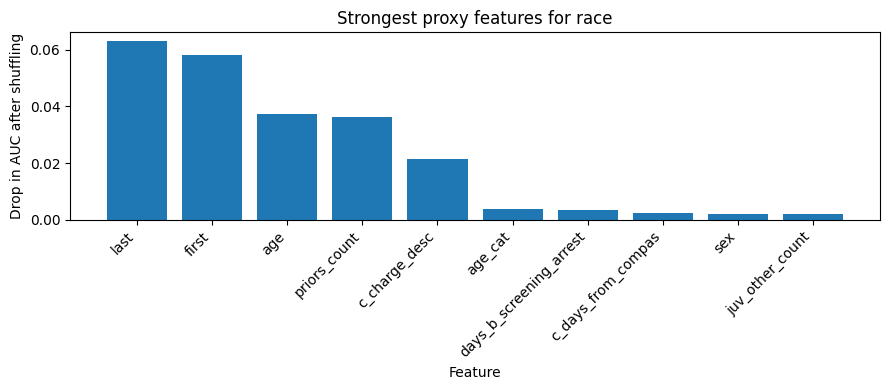

In [50]:
perm = permutation_importance(
    race_proxy_model,
    X_test_proxy,
    y_test_race,
    scoring="roc_auc",
    n_repeats=20,
    random_state=SEED
)

proxy_importance = pd.DataFrame({
    "feature": proxy_features,
    "importance": perm.importances_mean,
    "std": perm.importances_std
}).sort_values("importance", ascending=False)

print(proxy_importance.head(15).round(4))
plt.figure(figsize=(9, 4))
plt.bar(proxy_importance.head(10)["feature"], proxy_importance.head(10)["importance"])
plt.ylabel("Drop in AUC after shuffling")
plt.xlabel("Feature")
plt.title("Strongest proxy features for race")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [51]:
# without fist, last and name columns
drop_cols = drop_cols + ["first", "last", "name"]
proxy_features = [c for c in proxy_train.columns if c not in drop_cols]
proxy_features = [c for c in proxy_features if c in proxy_test.columns]
print("Number of proxy features:", len(proxy_features))
print(proxy_features)

X_train_proxy = proxy_train[proxy_features]
X_test_proxy = proxy_test[proxy_features]
num_cols = X_train_proxy.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = [c for c in proxy_features if c not in num_cols]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

race_proxy_model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=2000, random_state=SEED))
])

race_proxy_model.fit(X_train_proxy, y_train_race)
race_pred = race_proxy_model.predict(X_test_proxy)
race_prob = race_proxy_model.predict_proba(X_test_proxy)[:, 1]
print("\nProxy prediction: African-American vs Caucasian")
print("Accuracy:", round(accuracy_score(y_test_race, race_pred), 3))
print("AUC:", round(roc_auc_score(y_test_race, race_prob), 3))

Number of proxy features: 17
['sex', 'age', 'age_cat', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'v_screening_date', 'in_custody', 'out_custody', 'start', 'end', 'event']

Proxy prediction: African-American vs Caucasian
Accuracy: 0.629
AUC: 0.658


### Step2: Base Model

In [52]:
target_col = "two_year_recid"
protected_cols = ["race", "sex"]
drop_cols = [
    "two_year_recid",
    "is_recid",
    "is_violent_recid",
    "violent_recid",
    "decile_score",
    "decile_score.1",
    "score_text",
    "v_decile_score",
    "v_score_text",
    "id",
    "name",
    "first",
    "last",
    "dob",
    "compas_screening_date",
    "screening_date",
    "c_case_number",
    "c_offense_date",
    "c_arrest_date",
    "c_jail_in",
    "c_jail_out",
    "r_case_number",
    "r_charge_degree",
    "r_days_from_arrest",
    "r_offense_date",
    "r_charge_desc",
    "r_jail_in",
    "r_jail_out",
    "vr_case_number",
    "vr_charge_degree",
    "vr_offense_date",
    "vr_charge_desc",
    "type_of_assessment",
    "v_type_of_assessment",
    "event"
]

In [53]:
def divide(num1, num2):
    if num2 == 0:
        return np.nan
    return num1 / num2

In [54]:
feature_cols = [c for c in train_df.columns if c not in drop_cols]
feature_cols = [c for c in feature_cols if c in test_df.columns]
feature_cols = [c for c in feature_cols if train_df[c].notna().any() and test_df[c].notna().any()]
print("Number of model features:", len(feature_cols))
print(feature_cols)

Number of model features: 18
['sex', 'age', 'age_cat', 'race', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1', 'start', 'end']


In [55]:
X_train = train_df[feature_cols]
y_train = train_df[target_col].astype(int)
X_test = test_df[feature_cols]
y_test = test_df[target_col].astype(int)
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = [c for c in feature_cols if c not in num_cols]
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

baseline_model = Pipeline([
    ("preprocess", preprocess),
    ("clf", LogisticRegression(max_iter=2000, random_state=SEED))
])

baseline_model.fit(X_train, y_train)
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
print("Baseline Logistic Regression results")
print("Accuracy:", round(acc, 3))
print("ROC-AUC:", round(auc, 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=3))

Baseline Logistic Regression results
Accuracy: 0.89
ROC-AUC: 0.958

Confusion matrix:
[[604  69]
 [ 67 495]]

Classification report:
              precision    recall  f1-score   support

           0      0.900     0.897     0.899       673
           1      0.878     0.881     0.879       562

    accuracy                          0.890      1235
   macro avg      0.889     0.889     0.889      1235
weighted avg      0.890     0.890     0.890      1235



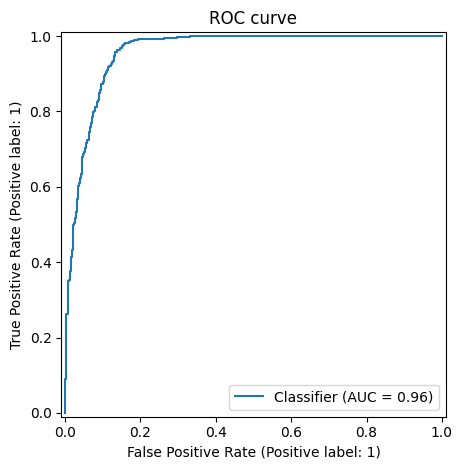

In [56]:
# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC curve")
plt.tight_layout()
plt.show()

In [57]:
def group_metrics(y_true, y_pred, groups):
    data = pd.DataFrame({
        "y_true": np.array(y_true).astype(int),
        "y_pred": np.array(y_pred).astype(int),
        "group": np.array(groups)
    })
    rows = []
    for g, part in data.groupby("group"):
        yt = part["y_true"].values
        yp = part["y_pred"].values
        tp = np.sum((yt == 1) & (yp == 1))
        fn = np.sum((yt == 1) & (yp == 0))
        tn = np.sum((yt == 0) & (yp == 0))
        fp = np.sum((yt == 0) & (yp == 1))
        n = len(part)

        # P(Y = 1 | A = g)
        base_rate = divide(tp + fn, n)

        # P(Y_hat = 1 | A = g)
        selection_rate = divide(tp + fp, n)

        # P(Y = 1 | Y_hat = 1, A = g)
        ppv = divide(tp, tp + fp)

        # P(Y_hat = 1 | Y = 1, A = g)
        tpr = divide(tp, tp + fn)

        # P(Y_hat = 1 | Y = 0, A = g)
        fpr = divide(fp, fp + tn)
        fnr = divide(fn, tp + fn)
        acc = divide(tp + tn, n)
        rows.append({
            "group": g,
            "n": n,
            "base_rate": base_rate,
            "selection_rate": selection_rate,
            "TPR": tpr,
            "FPR": fpr,
            "FNR": fnr,
            "PPV": ppv,
            "accuracy": acc,
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn
        })

    result = pd.DataFrame(rows)
    return result.sort_values("group").reset_index(drop=True)

In [58]:
race_metrics = group_metrics(
    y_true=np.array(y_test).astype(int),
    y_pred=np.array(y_pred).astype(int),
    groups=test_df["race"].values
)
print("Fairness metrics by race:")
print(race_metrics.round(3))

Fairness metrics by race:
              group    n  base_rate  selection_rate    TPR    FPR    FNR  \
0  African-American  635      0.523           0.521  0.904  0.102  0.096   
1             Asian    7      0.286           0.429  1.000  0.200  0.000   
2         Caucasian  420      0.390           0.410  0.866  0.117  0.134   
3          Hispanic  102      0.373           0.324  0.763  0.062  0.237   
4   Native American    2      0.500           0.500  1.000  0.000  0.000   
5             Other   69      0.362           0.348  0.840  0.068  0.160   

     PPV  accuracy   TP  FP   TN  FN  
0  0.906     0.901  300  31  272  32  
1  0.667     0.857    2   1    4   0  
2  0.826     0.876  142  30  226  22  
3  0.879     0.873   29   4   60   9  
4  1.000     1.000    1   0    1   0  
5  0.875     0.899   21   3   41   4  


In [59]:
sex_metrics = group_metrics(
    y_true=np.array(y_test).astype(int),
    y_pred=np.array(y_pred).astype(int),
    groups=test_df["sex"].values
)
print("Fairness metrics by sex:")
print(sex_metrics.round(3))

Fairness metrics by sex:
    group    n  base_rate  selection_rate    TPR    FPR    FNR    PPV  \
0  Female  238      0.349           0.374  0.904  0.090  0.096  0.843   
1    Male  997      0.480           0.476  0.877  0.106  0.123  0.884   

   accuracy   TP  FP   TN  FN  
0     0.908   75  14  141   8  
1     0.886  420  55  463  59  


### Step3: Fairness Through Unawareness Test

In [60]:
drop_cols_unaware = drop_cols + ["race", "sex"]
feature_cols_unaware = [c for c in train_df.columns if c not in drop_cols_unaware]
feature_cols_unaware = [c for c in feature_cols_unaware if c in test_df.columns]
feature_cols_unaware = [
    c for c in feature_cols_unaware
    if train_df[c].notna().any() and test_df[c].notna().any()
]

print("Number of features in unawareness model:", len(feature_cols_unaware))
print(feature_cols_unaware)


X_train_unaware = train_df[feature_cols_unaware]
y_train_unaware = train_df[target_col].astype(int)
X_test_unaware = test_df[feature_cols_unaware]
y_test_unaware = test_df[target_col].astype(int)
num_cols = X_train_unaware.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = [c for c in feature_cols_unaware if c not in num_cols]


num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])


unaware_model = Pipeline([
    ("preprocess", preprocess),
    ("clf", LogisticRegression(max_iter=2000, random_state=SEED))
])

unaware_model.fit(X_train_unaware, y_train_unaware)


y_pred_unaware = unaware_model.predict(X_test_unaware)
y_prob_unaware = unaware_model.predict_proba(X_test_unaware)[:, 1]

unaware_acc = accuracy_score(y_test_unaware, y_pred_unaware)
unaware_auc = roc_auc_score(y_test_unaware, y_prob_unaware)

print("Unawareness model results")
print("Accuracy:", round(unaware_acc, 3))
print("ROC-AUC:", round(unaware_auc, 3))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_unaware, y_pred_unaware))

print("\nClassification report:")
print(classification_report(y_test_unaware, y_pred_unaware, digits=3))

Number of features in unawareness model: 16
['age', 'age_cat', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1', 'start', 'end']
Unawareness model results
Accuracy: 0.89
ROC-AUC: 0.958

Confusion matrix:
[[605  68]
 [ 68 494]]

Classification report:
              precision    recall  f1-score   support

           0      0.899     0.899     0.899       673
           1      0.879     0.879     0.879       562

    accuracy                          0.890      1235
   macro avg      0.889     0.889     0.889      1235
weighted avg      0.890     0.890     0.890      1235



In [61]:
# Metrics by race
race_metrics = group_metrics(
    y_true=np.array(y_test_unaware).astype(int),
    y_pred=np.array(y_pred_unaware).astype(int),
    groups=test_df["race"].values
)
print("Fairness metrics by race:")
print(race_metrics.round(3))

Fairness metrics by race:
              group    n  base_rate  selection_rate    TPR    FPR    FNR  \
0  African-American  635      0.523           0.517  0.898  0.099  0.102   
1             Asian    7      0.286           0.429  1.000  0.200  0.000   
2         Caucasian  420      0.390           0.412  0.872  0.117  0.128   
3          Hispanic  102      0.373           0.324  0.763  0.062  0.237   
4   Native American    2      0.500           0.500  1.000  0.000  0.000   
5             Other   69      0.362           0.348  0.840  0.068  0.160   

     PPV  accuracy   TP  FP   TN  FN  
0  0.909     0.899  298  30  273  34  
1  0.667     0.857    2   1    4   0  
2  0.827     0.879  143  30  226  21  
3  0.879     0.873   29   4   60   9  
4  1.000     1.000    1   0    1   0  
5  0.875     0.899   21   3   41   4  


In [62]:
# Metrics by sex
sex_metrics = group_metrics(
    y_true=np.array(y_test_unaware).astype(int),
    y_pred=np.array(y_pred_unaware).astype(int),
    groups=test_df["sex"].values
)
print("\nFairness metrics by sex:")
print(sex_metrics.round(3))


Fairness metrics by sex:
    group    n  base_rate  selection_rate    TPR    FPR    FNR    PPV  \
0  Female  238      0.349           0.378  0.916  0.090  0.084  0.844   
1    Male  997      0.480           0.473  0.873  0.104  0.127  0.886   

   accuracy   TP  FP   TN  FN  
0     0.912   76  14  141   7  
1     0.885  418  54  464  61  


### Step4: Mitigation and Comparision

In [63]:
target_col = "two_year_recid"
feature_cols_mitigation = feature_cols_unaware.copy()
def group_gaps(metric_table):
    metric_names = ["selection_rate", "TPR", "FPR", "PPV"]
    rows = []

    for m in metric_names:
        vals = metric_table[m].dropna()
        rows.append({
            "metric": m,
            "min": vals.min(),
            "max": vals.max(),
            "gap": vals.max() - vals.min()
        })

    return pd.DataFrame(rows)


def build_lr_model(X_train):
    num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
    cat_cols = [c for c in X_train.columns if c not in num_cols]

    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocess = ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols)
    ])

    model = Pipeline([
        ("preprocess", preprocess),
        ("clf", LogisticRegression(max_iter=2000, random_state=SEED))
    ])

    return model


def fit_and_predict(train_part, test_part, feature_cols, sample_weight=None):
    X_tr = train_part[feature_cols]
    y_tr = train_part[target_col].astype(int)
    X_te = test_part[feature_cols]
    y_te = test_part[target_col].astype(int)
    model = build_lr_model(X_tr)

    if sample_weight is None:
        model.fit(X_tr, y_tr)
    else:
        model.fit(X_tr, y_tr, clf__sample_weight=sample_weight)

    prob = model.predict_proba(X_te)[:, 1]
    pred = (prob >= 0.5).astype(int)

    return model, pred, prob


def get_gaps_as_dict(prefix, metric_table):
    gaps = group_gaps(metric_table)
    out = {}

    for _, row in gaps.iterrows():
        out[f"{prefix}_{row['metric']}_gap"] = row["gap"]

    return out


def get_two_group_gap(metric_table, group1, group2, prefix):
    sub = metric_table[metric_table["group"].isin([group1, group2])].copy()
    out = {}
    for m in ["selection_rate", "TPR", "FPR", "PPV"]:
        vals = sub[m].dropna()
        if len(vals) == 2:
            out[f"{prefix}_{m}_gap"] = vals.max() - vals.min()
        else:
            out[f"{prefix}_{m}_gap"] = np.nan

    return out


def evaluate_method(method_name, y_true, y_pred, y_prob, test_part):
    acc_value = accuracy_score(y_true, y_pred)
    auc_value = roc_auc_score(y_true, y_prob)
    race_m = group_metrics(
        y_true=y_true,
        y_pred=y_pred,
        groups=test_part["race"].values
    )

    sex_m = group_metrics(
        y_true=y_true,
        y_pred=y_pred,
        groups=test_part["sex"].values
    )

    row = {
        "method": method_name,
        "accuracy": acc_value,
        "roc_auc": auc_value
    }
    row.update(get_gaps_as_dict("race_all", race_m))
    row.update(get_gaps_as_dict("sex", sex_m))
    row.update(get_two_group_gap(
        metric_table=race_m,
        group1="African-American",
        group2="Caucasian",
        prefix="race_AfricanAmerican_Caucasian"
    ))

    return row, race_m, sex_m

In [64]:
# Method 1: Pre-processing (Reweighing)
def compute_reweighing_weights(data, protected_attr, label_col):
    temp = data[[protected_attr, label_col]].copy()
    n = len(temp)
    a_counts = temp[protected_attr].value_counts()
    y_counts = temp[label_col].value_counts()
    ay_counts = temp.groupby([protected_attr, label_col]).size()
    weights = []

    for _, row in temp.iterrows():
        a = row[protected_attr]
        y = row[label_col]
        # w(a,y) = P(A=a)P(Y=y) / P(A=a,Y=y)
        w = (a_counts[a] * y_counts[y]) / (n * ay_counts[(a, y)])
        weights.append(w)

    return np.array(weights)


rw_weights = compute_reweighing_weights(
    data=train_df,
    protected_attr="race",
    label_col=target_col
)

print("Reweighing weights summary:")
print(pd.Series(rw_weights).describe())


rw_model, y_pred_rw, y_prob_rw = fit_and_predict(
    train_part=train_df,
    test_part=test_df,
    feature_cols=feature_cols_mitigation,
    sample_weight=rw_weights
)

y_test_stage4 = test_df[target_col].astype(int).values

print("Reweighing results")
print("Accuracy:", round(accuracy_score(y_test_stage4, y_pred_rw), 3))
print("ROC-AUC:", round(roc_auc_score(y_test_stage4, y_prob_rw), 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_test_stage4, y_pred_rw))
print("\nClassification report:")
print(classification_report(y_test_stage4, y_pred_rw, digits=3))

race_metrics_rw = group_metrics(
    y_true=y_test_stage4,
    y_pred=y_pred_rw,
    groups=test_df["race"].values
)

sex_metrics_rw = group_metrics(
    y_true=y_test_stage4,
    y_pred=y_pred_rw,
    groups=test_df["sex"].values
)

print("Race metrics after reweighing:")
print(race_metrics_rw.round(3))
print("\nSex metrics after reweighing:")
print(sex_metrics_rw.round(3))

Reweighing weights summary:
count    4937.000000
mean        1.000000
std         0.145501
min         0.726487
25%         0.869859
50%         0.894642
75%         1.142822
max         1.820539
dtype: float64
Reweighing results
Accuracy: 0.89
ROC-AUC: 0.957

Confusion matrix:
[[604  69]
 [ 67 495]]

Classification report:
              precision    recall  f1-score   support

           0      0.900     0.897     0.899       673
           1      0.878     0.881     0.879       562

    accuracy                          0.890      1235
   macro avg      0.889     0.889     0.889      1235
weighted avg      0.890     0.890     0.890      1235

Race metrics after reweighing:
              group    n  base_rate  selection_rate    TPR    FPR    FNR  \
0  African-American  635      0.523           0.513  0.895  0.096  0.105   
1             Asian    7      0.286           0.429  1.000  0.200  0.000   
2         Caucasian  420      0.390           0.417  0.878  0.121  0.122   
3          H

In [65]:
# Method 2: Post-processing (group threshold optimization)
def apply_group_thresholds(prob, groups, threshold_map, default_threshold=0.5):
    thresholds = np.array([
        threshold_map.get(g, default_threshold)
        for g in groups
    ])

    return (prob >= thresholds).astype(int)

def tune_equal_opportunity_thresholds(y_true_val, prob_val, group_val,
                                      main_groups=("African-American", "Caucasian"),
                                      default_threshold=0.5,
                                      max_acc_drop=0.03):
    y_true_val = np.array(y_true_val).astype(int)
    prob_val = np.array(prob_val)
    group_val = np.array(group_val)

    base_pred = (prob_val >= default_threshold).astype(int)
    base_acc = accuracy_score(y_true_val, base_pred)

    grid = np.round(np.linspace(0.05, 0.95, 91), 2)

    best = None
    best_info = None

    for t1 in grid:
        for t2 in grid:
            threshold_map = {
                main_groups[0]: t1,
                main_groups[1]: t2
            }

            pred = apply_group_thresholds(
                prob=prob_val,
                groups=group_val,
                threshold_map=threshold_map,
                default_threshold=default_threshold
            )
            acc_val = accuracy_score(y_true_val, pred)
            if acc_val < base_acc - max_acc_drop:
                continue
            metrics = group_metrics(y_true_val, pred, group_val)
            sub = metrics[metrics["group"].isin(main_groups)]

            if len(sub) < 2:
                continue

            tpr_gap = sub["TPR"].max() - sub["TPR"].min()
            score = (tpr_gap, -acc_val)
            if best is None or score < best:
                best = score
                best_info = {
                    "threshold_map": threshold_map,
                    "val_accuracy": acc_val,
                    "val_TPR_gap": tpr_gap,
                    "val_metrics": metrics
                }

    return best_info

split_key = train_df[target_col].astype(str) + "_" + train_df["race"].astype(str)
if split_key.value_counts().min() < 2:
    split_key = train_df[target_col].astype(str)

train_fit_df, val_df = train_test_split(
    train_df,
    test_size=0.25,
    random_state=SEED,
    stratify=split_key
)

tune_model, _, val_prob = fit_and_predict(
    train_part=train_fit_df,
    test_part=val_df,
    feature_cols=feature_cols_mitigation,
    sample_weight=None
)

threshold_info = tune_equal_opportunity_thresholds(
    y_true_val=val_df[target_col].astype(int).values,
    prob_val=val_prob,
    group_val=val_df["race"].values,
    main_groups=("African-American", "Caucasian"),
    default_threshold=0.5,
    max_acc_drop=0.03
)

print("Chosen thresholds:")
print(threshold_info["threshold_map"])
print("Validation accuracy:", round(threshold_info["val_accuracy"], 3))
print("Validation TPR gap:", round(threshold_info["val_TPR_gap"], 3))

print("\nValidation group metrics:")
print(threshold_info["val_metrics"].round(3))
post_model, _, y_prob_post = fit_and_predict(
    train_part=train_df,
    test_part=test_df,
    feature_cols=feature_cols_mitigation,
    sample_weight=None
)

y_pred_post = apply_group_thresholds(
    prob=y_prob_post,
    groups=test_df["race"].values,
    threshold_map=threshold_info["threshold_map"],
    default_threshold=0.5
)

print("\nPost-processing results")
print("Accuracy:", round(accuracy_score(y_test_stage4, y_pred_post), 3))
print("ROC-AUC:", round(roc_auc_score(y_test_stage4, y_prob_post), 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_test_stage4, y_pred_post))
print("\nClassification report:")
print(classification_report(y_test_stage4, y_pred_post, digits=3))

race_metrics_post = group_metrics(
    y_true=y_test_stage4,
    y_pred=y_pred_post,
    groups=test_df["race"].values
)

sex_metrics_post = group_metrics(
    y_true=y_test_stage4,
    y_pred=y_pred_post,
    groups=test_df["sex"].values
)

print("\nRace metrics after post-processing:")
print(race_metrics_post.round(3))
print("\nSex metrics after post-processing:")
print(sex_metrics_post.round(3))

Chosen thresholds:
{'African-American': 0.13, 'Caucasian': 0.17}
Validation accuracy: 0.864
Validation TPR gap: 0.0

Validation group metrics:
              group    n  base_rate  selection_rate    TPR    FPR    FNR  \
0  African-American  635      0.523           0.661  0.982  0.310  0.018   
1             Asian    6      0.167           0.167  1.000  0.000  0.000   
2         Caucasian  421      0.392           0.489  0.982  0.172  0.018   
3          Hispanic  102      0.373           0.402  0.868  0.125  0.132   
4   Native American    2      0.500           0.500  1.000  0.000  0.000   
5             Other   69      0.362           0.420  0.920  0.136  0.080   

     PPV  accuracy   TP  FP   TN  FN  
0  0.776     0.843  326  94  209   6  
1  1.000     1.000    1   0    5   0  
2  0.786     0.888  162  44  212   3  
3  0.805     0.873   33   8   56   5  
4  1.000     1.000    1   0    1   0  
5  0.793     0.884   23   6   38   2  

Post-processing results
Accuracy: 0.896
ROC-AUC: 0

In [66]:
stage4_rows = []
stage4_group_tables = {}
try:
    row, race_m, sex_m = evaluate_method(
        method_name="baseline_step2",
        y_true=np.array(y_test).astype(int),
        y_pred=np.array(y_pred).astype(int),
        y_prob=np.array(y_prob),
        test_part=test_df
    )
    stage4_rows.append(row)
    stage4_group_tables["baseline_step2_race"] = race_m
    stage4_group_tables["baseline_step2_sex"] = sex_m
except Exception as e:
    print("Could not add baseline_step2:", e)

try:
    row, race_m, sex_m = evaluate_method(
        method_name="unawareness_step3",
        y_true=np.array(y_test_unaware).astype(int),
        y_pred=np.array(y_pred_unaware).astype(int),
        y_prob=np.array(y_prob_unaware),
        test_part=test_df
    )
    stage4_rows.append(row)
    stage4_group_tables["unawareness_step3_race"] = race_m
    stage4_group_tables["unawareness_step3_sex"] = sex_m
except Exception as e:
    print("Could not add unawareness_step3:", e)

row, race_m, sex_m = evaluate_method(
    method_name="reweighing_race",
    y_true=y_test_stage4,
    y_pred=y_pred_rw,
    y_prob=y_prob_rw,
    test_part=test_df
)
stage4_rows.append(row)
stage4_group_tables["reweighing_race_race"] = race_m
stage4_group_tables["reweighing_race_sex"] = sex_m

row, race_m, sex_m = evaluate_method(
    method_name="postprocess_equal_opportunity",
    y_true=y_test_stage4,
    y_pred=y_pred_post,
    y_prob=y_prob_post,
    test_part=test_df
)
stage4_rows.append(row)
stage4_group_tables["postprocess_equal_opportunity_race"] = race_m
stage4_group_tables["postprocess_equal_opportunity_sex"] = sex_m


comparison_stage4 = pd.DataFrame(stage4_rows)
comparison_stage4_rounded = comparison_stage4.copy()
num_cols = comparison_stage4_rounded.select_dtypes(include=["float64", "float32"]).columns
comparison_stage4_rounded[num_cols] = comparison_stage4_rounded[num_cols].round(3)

print("Stage 4 comparison table:")
display(comparison_stage4_rounded)

Stage 4 comparison table:


,method,accuracy,roc_auc,race_all_selection_rate_gap,race_all_TPR_gap,race_all_FPR_gap,race_all_PPV_gap,sex_selection_rate_gap,sex_TPR_gap,sex_FPR_gap,sex_PPV_gap,race_AfricanAmerican_Caucasian_selection_rate_gap,race_AfricanAmerican_Caucasian_TPR_gap,race_AfricanAmerican_Caucasian_FPR_gap,race_AfricanAmerican_Caucasian_PPV_gap
0,baseline_step2,0.890,0.958,0.198,0.237,0.2,0.333,0.102,0.027,0.016,0.042,0.112,0.038,0.015,0.081
1,unawareness_step3,0.890,0.958,0.193,0.237,0.2,0.333,0.095,0.043,0.014,0.041,0.105,0.026,0.018,0.082
2,reweighing_race,0.890,0.957,0.170,0.211,0.2,0.333,0.097,0.041,0.016,0.040,0.097,0.017,0.025,0.088
3,postprocess_equal_opportunity,0.896,0.958,0.283,0.237,0.2,0.333,0.101,0.042,0.018,0.059,0.118,0.003,0.023,0.059


In [67]:
for name, table in stage4_group_tables.items():
    print("\n" + name)
    display(table.round(3))


baseline_step2_race


,group,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,TP,FP,TN,FN
0,African-American,635,0.523,0.521,0.904,0.102,0.096,0.906,0.901,300,31,272,32
1,Asian,7,0.286,0.429,1.000,0.200,0.000,0.667,0.857,2,1,4,0
2,Caucasian,420,0.390,0.410,0.866,0.117,0.134,0.826,0.876,142,30,226,22
3,Hispanic,102,0.373,0.324,0.763,0.062,0.237,0.879,0.873,29,4,60,9
4,Native American,2,0.500,0.500,1.000,0.000,0.000,1.000,1.000,1,0,1,0
5,Other,69,0.362,0.348,0.840,0.068,0.160,0.875,0.899,21,3,41,4



baseline_step2_sex


,group,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,TP,FP,TN,FN
0,Female,238,0.349,0.374,0.904,0.090,0.096,0.843,0.908,75,14,141,8
1,Male,997,0.480,0.476,0.877,0.106,0.123,0.884,0.886,420,55,463,59



unawareness_step3_race


...

,group,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,TP,FP,TN,FN
0,Female,238,0.349,0.378,0.916,0.090,0.084,0.844,0.912,76,14,141,7
1,Male,997,0.480,0.475,0.875,0.106,0.125,0.884,0.885,419,55,463,60



postprocess_equal_opportunity_race


,group,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,TP,FP,TN,FN
0,African-American,635,0.523,0.606,0.985,0.191,0.015,0.849,0.901,327,58,245,5
1,Asian,7,0.286,0.429,1.000,0.200,0.000,0.667,0.857,2,1,4,0
2,Caucasian,420,0.390,0.488,0.988,0.168,0.012,0.790,0.893,162,43,213,2
3,Hispanic,102,0.373,0.324,0.763,0.062,0.237,0.879,0.873,29,4,60,9
4,Native American,2,0.500,0.500,1.000,0.000,0.000,1.000,1.000,1,0,1,0
5,Other,69,0.362,0.348,0.840,0.068,0.160,0.875,0.899,21,3,41,4



postprocess_equal_opportunity_sex


,group,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,TP,FP,TN,FN
0,Female,238,0.349,0.445,1.000,0.148,0.000,0.783,0.903,83,23,132,0
1,Male,997,0.480,0.547,0.958,0.166,0.042,0.842,0.894,459,86,432,20


In [68]:
def aa_caucasian_gap_table(tables_dict):
    rows = []
    for method_name, race_table in tables_dict.items():
        if not method_name.endswith("_race"):
            continue
        sub = race_table[race_table["group"].isin(["African-American", "Caucasian"])].copy()
        if len(sub) != 2:
            continue
        row = {"method": method_name.replace("_race", "")}
        for m in ["selection_rate", "TPR", "FPR", "PPV"]:
            row[m + "_gap_AfricanAmerican_Caucasian"] = sub[m].max() - sub[m].min()
        rows.append(row)
    return pd.DataFrame(rows)

aa_cauc_gap = aa_caucasian_gap_table(stage4_group_tables)
display(aa_cauc_gap.round(3))

,method,selection_rate_gap_AfricanAmerican_Caucasian,TPR_gap_AfricanAmerican_Caucasian,FPR_gap_AfricanAmerican_Caucasian,PPV_gap_AfricanAmerican_Caucasian
0,baseline_step2,0.112,0.038,0.015,0.081
1,unawareness_step3,0.105,0.026,0.018,0.082
2,reweighing,0.097,0.017,0.025,0.088
3,postprocess_equal_opportunity,0.118,0.003,0.023,0.059


In [69]:
def sex_gap_table(tables_dict):
    rows = []
    for method_name, sex_table in tables_dict.items():
        if not method_name.endswith("_sex"):
            continue
        row = {"method": method_name.replace("_sex", "")}
        for m in ["selection_rate", "TPR", "FPR", "PPV"]:
            row[m + "_gap_sex"] = sex_table[m].max() - sex_table[m].min()
        rows.append(row)
    return pd.DataFrame(rows)

sex_gap = sex_gap_table(stage4_group_tables)
display(sex_gap.round(3))

,method,selection_rate_gap_sex,TPR_gap_sex,FPR_gap_sex,PPV_gap_sex
0,baseline_step2,0.102,0.027,0.016,0.042
1,unawareness_step3,0.095,0.043,0.014,0.041
2,reweighing_race,0.097,0.041,0.016,0.040
3,postprocess_equal_opportunity,0.101,0.042,0.018,0.059


### Step5: Trade-off

In [70]:
def tpr_for_group(y_true, y_pred):
    y_true = np.array(y_true).astype(int)
    y_pred = np.array(y_pred).astype(int)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    if tp + fn == 0:
        return np.nan

    return tp / (tp + fn)


def aa_caucasian_tpr_gap(y_true, y_pred, race_values):
    temp = pd.DataFrame({
        "y_true": np.array(y_true).astype(int),
        "y_pred": np.array(y_pred).astype(int),
        "race": np.array(race_values)
    })
    aa = temp[temp["race"] == "African-American"]
    cauc = temp[temp["race"] == "Caucasian"]
    tpr_aa = tpr_for_group(aa["y_true"], aa["y_pred"])
    tpr_cauc = tpr_for_group(cauc["y_true"], cauc["y_pred"])
    return abs(tpr_aa - tpr_cauc), tpr_aa, tpr_cauc


def get_pareto_frontier(df, gap_col="tpr_gap", acc_col="accuracy"):
    points = df.sort_values([gap_col, acc_col], ascending=[True, False]).copy()
    frontier_rows = []
    best_acc_so_far = -np.inf
    for _, row in points.iterrows():
        if row[acc_col] > best_acc_so_far:
            frontier_rows.append(row)
            best_acc_so_far = row[acc_col]

    return pd.DataFrame(frontier_rows)


thresholds = np.round(np.linspace(0.05, 0.95, 10), 2)
sweep_rows = []
y_true_sweep = np.array(y_test_unaware).astype(int)
prob_sweep = np.array(y_prob_unaware)
race_sweep = test_df["race"].values

for t in thresholds:
    pred_t = (prob_sweep >= t).astype(int)
    acc_t = accuracy_score(y_true_sweep, pred_t)
    gap_t, tpr_aa, tpr_cauc = aa_caucasian_tpr_gap(
        y_true=y_true_sweep,
        y_pred=pred_t,
        race_values=race_sweep
    )

    sweep_rows.append({
        "threshold": t,
        "accuracy": acc_t,
        "tpr_gap": gap_t,
        "TPR_African_American": tpr_aa,
        "TPR_Caucasian": tpr_cauc
    })

sweep_df = pd.DataFrame(sweep_rows)
sweep_df_rounded = sweep_df.round(3)

print("Threshold sweep results:")
display(sweep_df_rounded)

pareto_df = get_pareto_frontier(
    sweep_df,
    gap_col="tpr_gap",
    acc_col="accuracy"
)

print("Pareto frontier points:")
display(pareto_df.round(3))

Threshold sweep results:


,threshold,accuracy,tpr_gap,TPR_African_American,TPR_Caucasian
0,0.05,0.805,0.000,1.000,1.000
1,0.15,0.900,0.006,0.982,0.988
2,0.25,0.908,0.003,0.967,0.963
3,0.35,0.900,0.016,0.943,0.927
4,0.45,0.895,0.016,0.913,0.896
5,0.55,0.879,0.008,0.855,0.848
6,0.65,0.867,0.014,0.819,0.805
7,0.75,0.844,0.064,0.765,0.701
8,0.85,0.799,0.099,0.642,0.543
9,0.95,0.687,0.084,0.358,0.274


Pareto frontier points:


,threshold,accuracy,tpr_gap,TPR_African_American,TPR_Caucasian
0,0.05,0.805,0.000,1.000,1.000
2,0.25,0.908,0.003,0.967,0.963


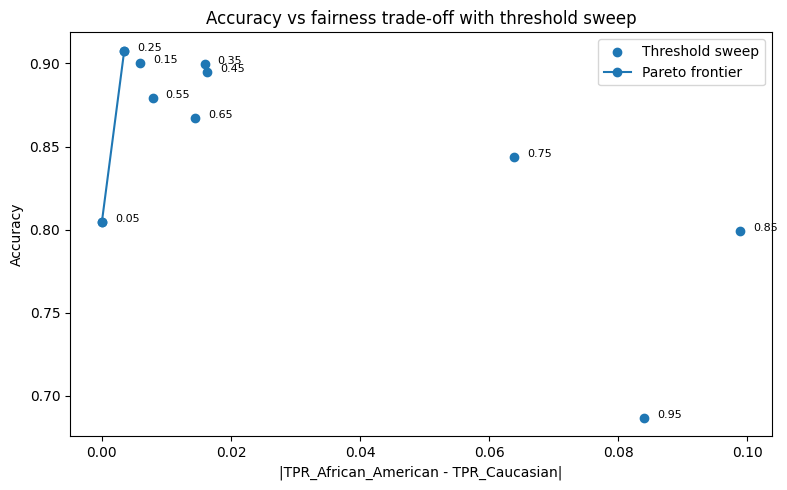

In [71]:
plt.figure(figsize=(8, 5))
plt.scatter(
    sweep_df["tpr_gap"],
    sweep_df["accuracy"],
    label="Threshold sweep"
)

for _, row in sweep_df.iterrows():
    plt.text(
        row["tpr_gap"] + 0.002,
        row["accuracy"],
        str(row["threshold"]),
        fontsize=8
    )

pareto_sorted = pareto_df.sort_values("tpr_gap")

plt.plot(
    pareto_sorted["tpr_gap"],
    pareto_sorted["accuracy"],
    marker="o",
    label="Pareto frontier"
)

plt.xlabel("|TPR_African_American - TPR_Caucasian|")
plt.ylabel("Accuracy")
plt.title("Accuracy vs fairness trade-off with threshold sweep")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
main_groups = ["African-American", "Caucasian"]
imp_df = test_df[test_df["race"].isin(main_groups)].copy()
mask = test_df["race"].isin(main_groups).values
y_true_imp = np.array(y_test_unaware).astype(int)[mask]
prob_imp = np.array(y_prob_unaware)[mask]
race_imp = test_df.loc[mask, "race"].values
def two_group_gaps(stats):
    aa = stats[stats["group"] == "African-American"].iloc[0]
    ca = stats[stats["group"] == "Caucasian"].iloc[0]

    return {
        "dp_gap": abs(aa["selection_rate"] - ca["selection_rate"]),
        "eo_gap": abs(aa["TPR"] - ca["TPR"]),
        "ppv_gap": abs(aa["PPV"] - ca["PPV"]),
        "fpr_gap": abs(aa["FPR"] - ca["FPR"]),
        "fnr_gap": abs(aa["FNR"] - ca["FNR"])
    }


def apply_two_thresholds(prob, groups, t_aa, t_cauc):
    pred = np.zeros(len(prob), dtype=int)

    aa_idx = groups == "African-American"
    ca_idx = groups == "Caucasian"

    pred[aa_idx] = (prob[aa_idx] >= t_aa).astype(int)
    pred[ca_idx] = (prob[ca_idx] >= t_cauc).astype(int)

    return pred


threshold_grid = np.round(np.linspace(0.01, 0.99, 99), 2)

rows = []

for t_aa in threshold_grid:
    for t_cauc in threshold_grid:
        pred_tmp = apply_two_thresholds(
            prob=prob_imp,
            groups=race_imp,
            t_aa=t_aa,
            t_cauc=t_cauc
        )

        stats_tmp = group_metrics(y_true_imp, pred_tmp, race_imp)
        gaps_tmp = two_group_gaps(stats_tmp)

        rows.append({
            "t_AfricanAmerican": t_aa,
            "t_Caucasian": t_cauc,
            "accuracy": np.mean(pred_tmp == y_true_imp),
            **gaps_tmp
        })

imposs_df = pd.DataFrame(rows)
imposs_df["max_three_gaps"] = imposs_df[["dp_gap", "eo_gap", "ppv_gap"]].max(axis=1)
imposs_df["sum_three_gaps"] = imposs_df[["dp_gap", "eo_gap", "ppv_gap"]].sum(axis=1)

best_all = imposs_df.sort_values(["max_three_gaps", "sum_three_gaps", "accuracy"],
                                 ascending=[True, True, False]).head(10).reset_index(drop=True)

print("Best threshold pairs for making DP gap, EO gap, and PPV gap small:")
display(best_all.round(4))


print("Demographic parity gap:")
display(imposs_df.sort_values(["dp_gap", "accuracy"], ascending=[True, False]).head(5).reset_index(drop=True).round(4))

print("Equal opportunity gap:")
display(imposs_df.sort_values(["eo_gap", "accuracy"], ascending=[True, False]).head(5).reset_index(drop=True).round(4))

print("PPV gap:")
display(imposs_df.sort_values(["ppv_gap", "accuracy"], ascending=[True, False]).head(5).reset_index(drop=True).round(4))


eps_list = [0.001, 0.005, 0.01, 0.02]
for eps in eps_list:
    ok = imposs_df[
        (imposs_df["dp_gap"] <= eps) &
        (imposs_df["eo_gap"] <= eps) &
        (imposs_df["ppv_gap"] <= eps)
    ]
    print(f"Number of threshold pairs with all three gaps <= {eps}: {len(ok)}")

Best threshold pairs for making DP gap, EO gap, and PPV gap small:


,t_AfricanAmerican,t_Caucasian,accuracy,dp_gap,eo_gap,ppv_gap,fpr_gap,fnr_gap,max_three_gaps,sum_three_gaps
0,0.98,0.98,0.5905,0.0327,0.0318,0.0208,0.0033,0.0318,0.0327,0.0854
1,0.99,0.99,0.5498,0.0212,0.0359,0.0000,0.0000,0.0359,0.0359,0.0571
2,0.97,0.96,0.6379,0.0268,0.0029,0.0361,0.0045,0.0029,0.0361,0.0658
3,0.97,0.97,0.6351,0.0435,0.0276,0.0127,0.0033,0.0276,0.0435,0.0837
4,0.96,0.95,0.6616,0.0448,0.0238,0.0427,0.0051,0.0238,0.0448,0.1113
5,0.97,0.95,0.6427,0.0101,0.0395,0.0498,0.0084,0.0395,0.0498,0.0994
6,0.96,0.93,0.6654,0.0305,0.0067,0.0543,0.0090,0.0067,0.0543,0.0914
7,0.99,0.98,0.5640,0.0145,0.0555,0.0000,0.0000,0.0555,0.0555,0.0700
8,0.96,0.94,0.6645,0.0329,0.0006,0.0557,0.0090,0.0006,0.0557,0.0891
9,0.96,0.96,0.6569,0.0614,0.0604,0.0290,0.0012,0.0604,0.0614,0.1508


Demographic parity gap:


,t_AfricanAmerican,t_Caucasian,accuracy,dp_gap,eo_gap,ppv_gap,fpr_gap,fnr_gap,max_three_gaps,sum_three_gaps
0,0.16,0.06,0.8616,0.0000,0.0211,0.2038,0.1610,0.0211,0.2038,0.2249
1,0.17,0.06,0.8616,0.0000,0.0211,0.2038,0.1610,0.0211,0.2038,0.2249
2,0.80,0.57,0.8455,0.0000,0.1185,0.1229,0.0704,0.1185,0.1229,0.2414
3,0.77,0.49,0.8569,0.0001,0.1341,0.1116,0.0644,0.1341,0.1341,0.2458
4,0.91,0.81,0.7668,0.0002,0.1008,0.1029,0.0427,0.1008,0.1029,0.2038


Equal opportunity gap:


,t_AfricanAmerican,t_Caucasian,accuracy,dp_gap,eo_gap,ppv_gap,fpr_gap,fnr_gap,max_three_gaps,sum_three_gaps
0,0.05,0.06,0.8076,0.1118,0.0,0.0834,0.0502,0.0,0.1118,0.1953
1,0.05,0.05,0.8038,0.1023,0.0,0.0938,0.0346,0.0,0.1023,0.1961
2,0.05,0.04,0.7905,0.0690,0.0,0.1275,0.0201,0.0,0.1275,0.1965
3,0.04,0.06,0.7886,0.1433,0.0,0.0519,0.1162,0.0,0.1433,0.1952
4,0.04,0.05,0.7848,0.1338,0.0,0.0622,0.1006,0.0,0.1338,0.1960


PPV gap:


,t_AfricanAmerican,t_Caucasian,accuracy,dp_gap,eo_gap,ppv_gap,fpr_gap,fnr_gap,max_three_gaps,sum_three_gaps
0,0.64,0.93,0.8133,0.3391,0.5234,0.0,0.0570,0.5234,0.5234,0.8626
1,0.81,0.96,0.7754,0.2898,0.4670,0.0,0.0318,0.4670,0.4670,0.7568
2,0.99,0.97,0.5791,0.0526,0.1531,0.0,0.0000,0.1531,0.1531,0.2057
3,0.99,0.98,0.5640,0.0145,0.0555,0.0,0.0000,0.0555,0.0555,0.0700
4,0.99,0.99,0.5498,0.0212,0.0359,0.0,0.0000,0.0359,0.0359,0.0571


Number of threshold pairs with all three gaps <= 0.001: 0
Number of threshold pairs with all three gaps <= 0.005: 0
Number of threshold pairs with all three gaps <= 0.01: 0
Number of threshold pairs with all three gaps <= 0.02: 0


In [73]:
best_row = best_all.iloc[0]
best_pred = apply_two_thresholds(
    prob=prob_imp,
    groups=race_imp,
    t_aa=best_row["t_AfricanAmerican"],
    t_cauc=best_row["t_Caucasian"]
)
best_stats = group_metrics(y_true_imp, best_pred, race_imp)
print("Best chosen thresholds:")
print("African-American threshold:", best_row["t_AfricanAmerican"])
print("Caucasian threshold:", best_row["t_Caucasian"])
print("\nGroup metrics at best threshold pair:")
display(best_stats.round(4))

Best chosen thresholds:
African-American threshold: 0.98
Caucasian threshold: 0.98

Group metrics at best threshold pair:


,group,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,TP,FP,TN,FN
0,African-American,635,0.5228,0.0756,0.1416,0.0033,0.8584,0.9792,0.5496,47,1,302,285
1,Caucasian,420,0.3905,0.0429,0.1098,0.0000,0.8902,1.0000,0.6524,18,0,256,146


In [74]:
def chouldechova_check(stats):
    rows = []
    for _, r in stats.iterrows():
        p = r["base_rate"]
        ppv = r["PPV"]
        fnr = r["FNR"]
        fpr = r["FPR"]

        if pd.isna(ppv) or ppv == 0 or p == 1:
            rhs = np.nan
        else:
            rhs = (p / (1 - p)) * ((1 - ppv) / ppv) * (1 - fnr)
        rows.append({
            "group": r["group"],
            "base_rate_p": p,
            "FPR_observed": fpr,
            "FNR_observed": fnr,
            "PPV_observed": ppv,
            "FPR_from_identity": rhs,
            "absolute_error": abs(fpr - rhs) if not pd.isna(rhs) else np.nan
        })

    return pd.DataFrame(rows)

identity_table = chouldechova_check(best_stats)
print("Chouldechova check:")
display(identity_table.round(6))

Chouldechova check:


,group,base_rate_p,FPR_observed,FNR_observed,PPV_observed,FPR_from_identity,absolute_error
0,African-American,0.522835,0.0033,0.858434,0.979167,0.0033,0.0
1,Caucasian,0.390476,0.0000,0.890244,1.000000,0.0000,0.0


### Step6

In [ ]:
y_true_best = np.array(y_test_stage4).astype(int)
y_pred_best = np.array(y_pred_post).astype(int)
audit_intersection_df = test_df.copy()
audit_intersection_df["race_sex"] = (
    audit_intersection_df["race"].astype(str) + " | " +
    audit_intersection_df["sex"].astype(str)
)

def gap_table(metrics_df, min_n=1):
    sub = metrics_df[metrics_df["n"] >= min_n].copy()

    rows = []
    for m in ["selection_rate", "TPR", "FPR", "FNR", "PPV", "accuracy"]:
        vals = sub[m].dropna()
        rows.append({
            "metric": m,
            "min": vals.min(),
            "max": vals.max(),
            "gap": vals.max() - vals.min()
        })

    return pd.DataFrame(rows)


race_best_metrics = group_metrics(
    y_true=y_true_best,
    y_pred=y_pred_best,
    groups=audit_intersection_df["race"].values
)

sex_best_metrics = group_metrics(
    y_true=y_true_best,
    y_pred=y_pred_best,
    groups=audit_intersection_df["sex"].values
)

intersection_metrics = group_metrics(
    y_true=y_true_best,
    y_pred=y_pred_best,
    groups=audit_intersection_df["race_sex"].values
)

print("Marginal metrics by race:")
display(race_best_metrics.round(3))

print("Marginal metrics by sex:")
display(sex_best_metrics.round(3))

print("Intersectional metrics by race x sex:")
display(intersection_metrics.round(3))

Marginal metrics by race:


,group,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,TP,FP,TN,FN
0,African-American,635,0.523,0.606,0.985,0.191,0.015,0.849,0.901,327,58,245,5
1,Asian,7,0.286,0.429,1.000,0.200,0.000,0.667,0.857,2,1,4,0
2,Caucasian,420,0.390,0.488,0.988,0.168,0.012,0.790,0.893,162,43,213,2
3,Hispanic,102,0.373,0.324,0.763,0.062,0.237,0.879,0.873,29,4,60,9
4,Native American,2,0.500,0.500,1.000,0.000,0.000,1.000,1.000,1,0,1,0
5,Other,69,0.362,0.348,0.840,0.068,0.160,0.875,0.899,21,3,41,4


Marginal metrics by sex:


,group,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,TP,FP,TN,FN
0,Female,238,0.349,0.445,1.000,0.148,0.000,0.783,0.903,83,23,132,0
1,Male,997,0.480,0.547,0.958,0.166,0.042,0.842,0.894,459,86,432,20


Intersectional metrics by race x sex:


,group,n,base_rate,selection_rate,TPR,FPR,FNR,PPV,accuracy,TP,FP,TN,FN
0,African-American | Female,116,0.353,0.466,1.000,0.173,0.000,0.759,0.888,41,13,62,0
1,African-American | Male,519,0.561,0.638,0.983,0.197,0.017,0.864,0.904,286,45,183,5
2,Asian | Male,7,0.286,0.429,1.000,0.200,0.000,0.667,0.857,2,1,4,0
3,Caucasian | Female,104,0.375,0.471,1.000,0.154,0.000,0.796,0.904,39,10,55,0
4,Caucasian | Male,316,0.396,0.494,0.984,0.173,0.016,0.788,0.889,123,33,158,2
5,Hispanic | Female,10,0.100,0.100,1.000,0.000,0.000,1.000,1.000,1,0,9,0
6,Hispanic | Male,92,0.402,0.348,0.757,0.073,0.243,0.875,0.859,28,4,51,9
7,Native American | Male,2,0.500,0.500,1.000,0.000,0.000,1.000,1.000,1,0,1,0
8,Other | Female,8,0.250,0.250,1.000,0.000,0.000,1.000,1.000,2,0,6,0
9,Other | Male,61,0.377,0.361,0.826,0.079,0.174,0.864,0.885,19,3,35,4


In [ ]:
race_gap = gap_table(race_best_metrics, min_n=1)
sex_gap = gap_table(sex_best_metrics, min_n=1)

intersection_gap = gap_table(intersection_metrics, min_n=1)
print("Race marginal gaps:")
display(race_gap.round(3))

print("Sex marginal gaps:")
display(sex_gap.round(3))

print("Intersectional gaps over all race x sex groups:")
display(intersection_gap.round(3))

Race marginal gaps:


,metric,min,max,gap
0,selection_rate,0.324,0.606,0.283
1,TPR,0.763,1.000,0.237
2,FPR,0.000,0.200,0.200
3,FNR,0.000,0.237,0.237
4,PPV,0.667,1.000,0.333
5,accuracy,0.857,1.000,0.143


Sex marginal gaps:


,metric,min,max,gap
0,selection_rate,0.445,0.547,0.101
1,TPR,0.958,1.000,0.042
2,FPR,0.148,0.166,0.018
3,FNR,0.000,0.042,0.042
4,PPV,0.783,0.842,0.059
5,accuracy,0.894,0.903,0.010


Intersectional gaps over all race x sex groups:


,metric,min,max,gap
0,selection_rate,0.100,0.638,0.538
1,TPR,0.757,1.000,0.243
2,FPR,0.000,0.200,0.200
3,FNR,0.000,0.243,0.243
4,PPV,0.667,1.000,0.333
5,accuracy,0.857,1.000,0.143


In [ ]:
def make_gap_summary(name, metrics_df, min_n=1):
    g = gap_table(metrics_df, min_n=min_n)
    out = {"audit_level": name, "min_n": min_n}

    for _, row in g.iterrows():
        out[row["metric"] + "_gap"] = row["gap"]

    return out
gap_summary_rows = [
    make_gap_summary("race", race_best_metrics, min_n=1),
    make_gap_summary("sex", sex_best_metrics, min_n=1),
    make_gap_summary("race_x_sex_all", intersection_metrics, min_n=1),
    make_gap_summary("race_x_sex_n>=30", intersection_metrics, min_n=30)
]

gap_summary = pd.DataFrame(gap_summary_rows)
print("Marginal vs intersectional gap summary:")
display(gap_summary.round(3))

Marginal vs intersectional gap summary:


,audit_level,min_n,selection_rate_gap,TPR_gap,FPR_gap,FNR_gap,PPV_gap,accuracy_gap
0,race,1,0.283,0.237,0.200,0.237,0.333,0.143
1,sex,1,0.101,0.042,0.018,0.042,0.059,0.010
2,race_x_sex_all,1,0.538,0.243,0.200,0.243,0.333,0.143
3,race_x_sex_n>=30,30,0.290,0.243,0.125,0.243,0.116,0.045
